# Классификация ботов

Условие и описание метрики — в `README.md`.

In [19]:
import numpy as np
import pandas as pd
import optuna
from catboost import CatBoostClassifier
from metric import precision_at_recall
RANDOM_STATE = 0


train = pd.read_csv('../data/train.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])
test = pd.read_csv('../data/test.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])
events = pd.read_csv('../data/events.csv.gz', parse_dates=['event_ts'])

print(train.shape, test.shape, events.shape)
print('доля ботов в train:', train.target.mean().round(4))
train.head()

(11091, 5) (4909, 4) (328905, 14)
доля ботов в train: 0.0811


,cookie_id,cookie_created_at,window_start_ts,window_end_ts,target
0,ck_54a059eb7d3ea68b,2025-11-21 09:30:41,2026-04-06,2026-04-07,0
1,ck_7e4de46eeab82974,2025-09-23 10:10:24,2026-04-06,2026-04-07,0
2,ck_9320229ef6304522,2026-03-04 00:08:02,2026-04-06,2026-04-07,0
3,ck_30ccd25bc1714ed9,2026-04-05 10:52:40,2026-04-06,2026-04-07,0
4,ck_a77c5f05948cdeef,2026-01-01 03:54:35,2026-04-06,2026-04-07,0


Посмотрим на баланс классов

In [20]:
train['target'].value_counts() / train.shape[0]

target
0    0.918943
1    0.081057
Name: count, dtype: float64

Видно, что есть дисбаланс классов

Теперь удалим полные дубликаты строк и добавим полезные в будующем для агрегаций фичи

In [21]:
events = events.drop_duplicates()
events['platform'] = events['platform'].str.lower()
events['platform'] = np.where(events['platform'] == 'desktop', 'web', events['platform'])
events['platform'] = np.where(events['platform'] == 'iphone', 'ios', events['platform'])
events['is_view'] = np.where(events['event_name'] == 'item_view', 1, 0)
events['is_search'] = np.where(events['event_name'] == 'search_results_view', 1, 0)
events['no_ptr_x'] = np.where(events['pointer_x'].isna(), 1, 0)
events['no_ptr_y'] = np.where(events['pointer_y'].isna(), 1, 0)
events['ptr_edge'] = (
    events.pointer_x.le(5) | events.pointer_x.ge(1915) |
    events.pointer_y.le(5) | events.pointer_y.ge(1075)
).where(events.pointer_x.notna())
events['is_not_web'] = np.where(events['platform'] != 'web', 1, 0)


events = events.drop(columns=['user_agent', 'eid'])

In [22]:
events.head()

,cookie_id,event_ts,event_name,platform,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y,is_view,is_search,no_ptr_x,no_ptr_y,ptr_edge,is_not_web
0,ck_5efbea1befdefe1b,2026-04-26 09:11:24,item_view,web,1027450.0,elektronika,kaliningrad,pro,NaN,NaN,NaN,NaN,1,0,1,1,NaN,0
1,ck_c4ca1434f3778f1d,2026-04-20 14:04:31,search_results_view,web,NaN,telefony,habarovsk,NaN,iphone 13 128,4.0,NaN,NaN,0,1,1,1,NaN,0
2,ck_d274382b19488771,2026-04-13 12:02:56,item_view,web,1048743.0,kvartiry_prodazha,kirov,private,NaN,NaN,675.0,276.0,1,0,0,0,False,0
3,ck_fbbed2ff14944ce9,2026-04-08 06:12:14,search_results_view,web,NaN,bytovaya_tehnika,novosibirsk,NaN,пылесос dyson,2.0,NaN,NaN,0,1,1,1,NaN,0
4,ck_56cc15c7c634cb9f,2026-04-12 17:16:05,search_results_view,web,NaN,odezhda,sankt-peterburg,NaN,костюм мужской,2.0,NaN,NaN,0,1,1,1,NaN,0


## Осмотреться

Прежде чем считать агрегаты, стоит посмотреть на данные: какие типы событий бывают, что
лежит в `platform` и `user_agent`, где пропуски, всё ли уникально.

In [23]:
print(events.event_name.value_counts(), '\n')
print(events.platform.value_counts(), '\n')
print('пропуски по колонкам:')
print(events.isna().mean().round(3))

event_name
item_view               118990
search_results_view      98929
photo_swipe              35962
favorite_add             18739
seller_page_view         17180
contact_phone_show       11154
captcha_shown             7831
login                     6178
contact_chat_open         6047
contact_message_sent      3032
Name: count, dtype: int64 

platform
web        182943
android    124988
ios         16111
Name: count, dtype: int64 

пропуски по колонкам:
cookie_id        0.000
event_ts         0.000
event_name       0.000
platform         0.000
item_id          0.349
item_category    0.100
item_location    0.072
seller_type      0.407
search_query     0.695
search_page      0.695
pointer_x        0.670
pointer_y        0.670
is_view          0.000
is_search        0.000
no_ptr_x         0.000
no_ptr_y         0.000
ptr_edge         0.670
is_not_web       0.000
dtype: float64


## Окно наблюдения

Признаки считаем только по событиям внутри окна: `window_start_ts <= event_ts < window_end_ts`.
Это требование из условия, а не рекомендация.

In [24]:
def events_in_window(events, meta):
    ev = events.merge(meta[['cookie_id', 'window_start_ts', 'window_end_ts']], on='cookie_id')
    return ev[(ev.event_ts >= ev.window_start_ts) & (ev.event_ts < ev.window_end_ts)]

ev_tr = events_in_window(events, train).sort_values(by=['cookie_id', 'event_ts'])
ev_te = events_in_window(events, test).sort_values(by=['cookie_id', 'event_ts'])
ev_tr['dt'] = ev_tr.groupby('cookie_id').event_ts.diff().dt.total_seconds()
ev_te['dt'] = ev_te.groupby('cookie_id').event_ts.diff().dt.total_seconds()
print(len(ev_tr), len(ev_te))

195484 88349


In [25]:
ev_tr.head()

,cookie_id,event_ts,event_name,platform,item_id,item_category,item_location,seller_type,search_query,search_page,...,pointer_y,is_view,is_search,no_ptr_x,no_ptr_y,ptr_edge,is_not_web,window_start_ts,window_end_ts,dt
187238,ck_000c95f1408dcb00,2026-04-19 14:49:54,search_results_view,web,NaN,hobbi,NaN,NaN,гитара акустическая,2.0,...,1059.0,0,1,0,0,False,0,2026-04-19,2026-04-20,NaN
47793,ck_000c95f1408dcb00,2026-04-19 14:50:17,photo_swipe,web,1021247.0,mebel,samara,private,NaN,NaN,...,674.0,0,0,0,0,False,0,2026-04-19,2026-04-20,23.0
142511,ck_000c95f1408dcb00,2026-04-19 15:50:21,item_view,web,1021247.0,mebel,samara,private,NaN,NaN,...,218.0,1,0,0,0,False,0,2026-04-19,2026-04-20,3604.0
133836,ck_000c95f1408dcb00,2026-04-19 15:50:47,item_view,web,1050338.0,mebel,volgograd,private,NaN,NaN,...,372.0,1,0,0,0,False,0,2026-04-19,2026-04-20,26.0
154464,ck_000c95f1408dcb00,2026-04-19 15:51:45,item_view,web,1050338.0,NaN,volgograd,private,NaN,NaN,...,1021.0,1,0,0,0,False,0,2026-04-19,2026-04-20,58.0


## Признаки

Будем смотреть на **позицию координат мыши**, а также на **разброс координат**, также важно смотреть на **медиану** и **5-ый перцентиль времени между запросами**, тк скорее всего боты и агрегаторы делают запросы крайне быстро, также имеет смысл смотреть на **уникальные количества фич в окне** по типу количества продавцов, категорий предметов и тд

In [26]:
def features(ev, meta):
    g = ev.groupby('cookie_id')
    f = pd.DataFrame({
        'n_events': g.size(),
        'item_nunique': g.item_id.nunique(),
        'item_categories': g.item_category.nunique(),
        'item_search_ratio': g.search_query.nunique() / (g.item_id.nunique() + 1),
        'loc_nunique': g.item_location.nunique(),
        'n_views': g.is_view.sum(),
        'avg_page': g.search_page.mean(),
        'seller_nunique': g.seller_type.nunique(),
        'avg_mobile': g.is_not_web.mean(),
        'q_nunique': g.search_query.nunique(),
        'dt_median': g.dt.median(),
        'dt_q_005': g.dt.quantile(0.05),
        'dt_q_075': g.dt.quantile(0.75),
        'ptr_x_std': g.pointer_x.std(),
        'ptr_y_std': g.pointer_y.std(),
        'dt_mode_share': g.dt.agg(lambda s: s.value_counts(normalize=True).iloc[0] 
                        if s.notna().any() else np.nan),
        'edge_share': g.ptr_edge.mean(),
        
    })
    
    f['search_view_ratio'] = f.q_nunique / (f.n_views + 1)

    shares = ev.groupby(['cookie_id', 'event_name']).size().unstack(fill_value=0)
    shares = shares.div(shares.sum(axis=1), axis=0).add_prefix('r_')
    f = f.join(shares)

    f = meta[['cookie_id']].merge(f.reset_index(), on='cookie_id', how='left')
    return f

Xtr = features(ev_tr, train)
Xte = features(ev_te, test)
ytr = train.target.values
Xtr.head()

,cookie_id,n_events,item_nunique,item_categories,item_search_ratio,loc_nunique,n_views,avg_page,seller_nunique,avg_mobile,...,search_view_ratio,r_contact_chat_open,r_contact_message_sent,r_contact_phone_show,r_favorite_add,r_item_view,r_login,r_photo_swipe,r_search_results_view,r_seller_page_view
0,ck_54a059eb7d3ea68b,7,4,3,0.600000,5,3,3.000000,2,1.0,...,0.750000,0.000000,0.000000,0.000000,0.000000,0.428571,0.000000,0.142857,0.428571,0.000000
1,ck_7e4de46eeab82974,41,19,1,0.250000,12,22,3.625000,2,0.0,...,0.217391,0.000000,0.000000,0.024390,0.024390,0.536585,0.024390,0.097561,0.195122,0.097561
2,ck_9320229ef6304522,36,19,7,0.500000,9,7,3.538462,2,0.0,...,1.250000,0.027778,0.027778,0.055556,0.083333,0.194444,0.083333,0.083333,0.361111,0.083333
3,ck_30ccd25bc1714ed9,21,10,1,0.272727,4,14,1.666667,2,0.0,...,0.200000,0.047619,0.000000,0.047619,0.000000,0.666667,0.000000,0.000000,0.142857,0.095238
4,ck_a77c5f05948cdeef,28,16,4,0.352941,6,12,2.833333,2,0.0,...,0.461538,0.000000,0.000000,0.035714,0.071429,0.428571,0.000000,0.142857,0.214286,0.107143


## Валидация и подбор гиперпараметров

Тест лежит **позже** трейна по времени, поэтому и валидацию честно делать по времени, а не
случайным сплитом.

Метрику берём из `metric.py` — это ровно тот код, которым считает проверяющая система.
Своя реализация почти наверняка разойдётся с официальной на одинаковых `score`:
их нельзя разделять, группа равных значений отмечается целиком.


Для подбора гиперпараметров буду юзать **оптюну**, тк она наиболее эффективно находит гиперпараметры в большом пространстве.

Для валидации **разобьем данные на фолды по времени** (чтобы не было лика) и в конце усредним

In [28]:
cols = ['n_events', 'item_nunique', 'n_views', 'q_nunique', 
        'dt_median', 'search_view_ratio', 'item_categories', 
        'ptr_x_std', 'ptr_y_std', 'dt_q_005', 'item_search_ratio',
        'avg_page', 'avg_mobile', 'seller_nunique', 'edge_share',
        'loc_nunique', 'dt_q_075', 'dt_mode_share']

d = train.window_start_ts
folds = [
    (d.lt('2026-04-10').values, (d.ge('2026-04-10') & d.lt('2026-04-13')).values),
    (d.lt('2026-04-13').values, (d.ge('2026-04-13') & d.lt('2026-04-17')).values),
    (d.lt('2026-04-17').values,  d.ge('2026-04-17').values),
]

def cv_score(params, cols=cols):
    scores = []
    for tr_m, va_m in folds:
        model = CatBoostClassifier(**params, verbose = False, allow_writing_files=False)
        model.fit(Xtr.loc[tr_m, cols], ytr[tr_m])
        p = model.predict_proba(Xtr.loc[va_m, cols])[:, 1]
        scores.append(precision_at_recall(ytr[va_m], p))
    return np.mean(scores), np.round(scores, 3)


def objective(trial, seed: int = RANDOM_STATE):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 200, 1000),
        "learning_rate": trial.suggest_float("learning_rate", 1e-2, 1e-1, log=True),
        "depth": trial.suggest_int("depth", 3, 6),
        "random_seed": seed,
    }
    
    return cv_score(params)[0]

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50, show_progress_bar=True)

print('лучшие:       ', study.best_params)
print('до подбора:   ', cv_score({'random_seed': 0}))
print('после подбора:', cv_score({**study.best_params, 'random_seed': 0}))


[I 2026-09-28 22:45:39,246] A new study created in memory with name: no-name-b7c60856-d2bb-47a7-a2fa-cbbf89f5f208
Best trial: 0. Best value: 0.705524:   2%|▏         | 1/50 [00:01<01:35,  1.94s/it]

[I 2026-09-28 22:45:41,183] Trial 0 finished with value: 0.7055244650570603 and parameters: {'n_estimators': 690, 'learning_rate': 0.022824218627370618, 'depth': 6}. Best is trial 0 with value: 0.7055244650570603.


Best trial: 0. Best value: 0.705524:   4%|▍         | 2/50 [00:03<01:13,  1.53s/it]

[I 2026-09-28 22:45:42,427] Trial 1 finished with value: 0.680189128683935 and parameters: {'n_estimators': 587, 'learning_rate': 0.05141114648288887, 'depth': 3}. Best is trial 0 with value: 0.7055244650570603.


Best trial: 0. Best value: 0.705524:   6%|▌         | 3/50 [00:03<00:49,  1.05s/it]

[I 2026-09-28 22:45:42,907] Trial 2 finished with value: 0.6657958374532622 and parameters: {'n_estimators': 225, 'learning_rate': 0.04807496692931247, 'depth': 3}. Best is trial 0 with value: 0.7055244650570603.


... (90 outputs left out)

Best trial: 34. Best value: 0.7248:  98%|█████████▊| 49/50 [01:43<00:02,  2.54s/it]

[I 2026-09-28 22:47:23,114] Trial 48 finished with value: 0.7099805143502622 and parameters: {'n_estimators': 991, 'learning_rate': 0.010369725030268645, 'depth': 6}. Best is trial 34 with value: 0.7248000143343991.


Best trial: 34. Best value: 0.7248: 100%|██████████| 50/50 [01:45<00:00,  2.11s/it]


[I 2026-09-28 22:47:24,517] Trial 49 finished with value: 0.7167075563515829 and parameters: {'n_estimators': 484, 'learning_rate': 0.019503314580404357, 'depth': 6}. Best is trial 34 with value: 0.7248000143343991.
лучшие:        {'n_estimators': 917, 'learning_rate': 0.01702050381583308, 'depth': 6}
до подбора:    (np.float64(0.6994256700139053), array([0.725, 0.641, 0.732]))
после подбора: (np.float64(0.7248000143343991), array([0.751, 0.649, 0.774]))


## Сабмит


Для сабмита обучим модельку на всем трейне с подобранными гиперпараметрами и запишем результат в **submission.csv**

In [29]:
model = CatBoostClassifier(**study.best_params, verbose=False)
model.fit(Xtr[cols], ytr)
sub = pd.DataFrame({
    'cookie_id': Xte.cookie_id,
    'score': model.predict_proba(Xte[cols])[:, 1],
})
assert len(sub) == len(test) and sub.score.between(0, 1).all()
sub.to_csv('../res/submission.csv', index=False)
sub.head()

,cookie_id,score
0,ck_315fb710a0e371e7,0.000898
1,ck_a76ee3b3e3e522fd,0.111448
2,ck_94c9a4d382689e82,0.026668
3,ck_8eaf9509ad9462a0,0.000571
4,ck_9a88a5a989cb5bc6,0.008926


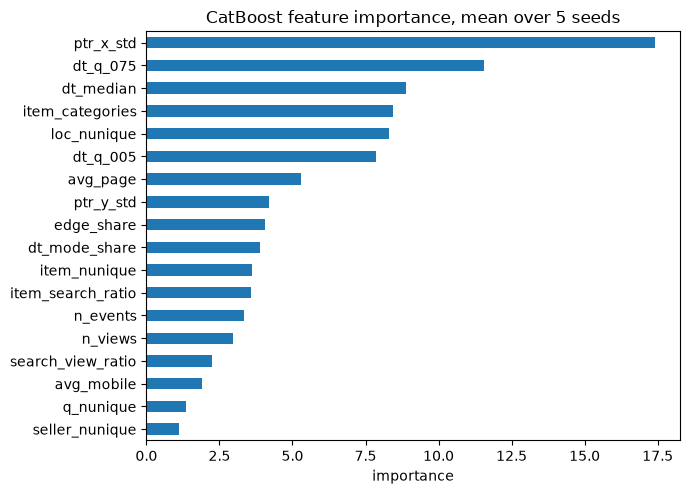

ptr_x_std            17.39
dt_q_075             11.56
dt_median             8.88
item_categories       8.44
loc_nunique           8.32
dt_q_005              7.87
avg_page              5.27
ptr_y_std             4.18
edge_share            4.05
dt_mode_share         3.88
item_nunique          3.60
item_search_ratio     3.58
n_events              3.34
n_views               2.98
search_view_ratio     2.25
avg_mobile            1.91
q_nunique             1.37
seller_nunique        1.12
dtype: float64

In [30]:
import matplotlib.pyplot as plt

imps = []
for s in range(5):
    m = CatBoostClassifier(**study.best_params, random_seed=s, verbose=False, allow_writing_files=False)
    m.fit(Xtr[cols], ytr)
    imps.append(m.get_feature_importance())

fi = pd.Series(np.mean(imps, axis=0), index=cols).sort_values()

fig, ax = plt.subplots(figsize=(7, len(cols) * 0.28))
fi.plot.barh(ax=ax)
ax.set_xlabel('importance')
ax.set_title('CatBoost feature importance, mean over 5 seeds')
plt.tight_layout()
plt.show()

fi.sort_values(ascending=False).round(2)